![Banner](../../../../Images/Banner/07_remote_sensing/09_02_banner_rs_optical.png)


# Landsat: Half a Century of Earth Observation

Landsat is the longest continuous record of Earth's land surface from space: from Landsat 1 in 1972 to Landsat 9 today, at 30 m resolution with free, consistently calibrated data.


## Overview

This module covers the Landsat archive, Collection 2 products, scale factors, QA decoding, composites, spectral indices, surface temperature, and two real multi-decade change analyses.


## Core concepts

### Learning objectives

1. Know the Landsat missions, sensors, band layouts and Collection 2 processing levels.
2. Apply Collection 2 Level-2 scale factors for reflectance and surface temperature.
3. Decode `QA_PIXEL` bit flags and build cloud masks.
4. Make and interpret natural- and false-colour composites.
5. Compute, compare and validate spectral indices for vegetation, water and built-up land.
6. Understand land surface temperature retrieval and analyse a real LST product.
7. Analyse multi-decade change from real Landsat time series in the Pucallpa and Bangladesh delta capstones.

### Contents

1. The program
2. Platforms
3. Sensors
4. Spectral bands
5. Data products
6. Applications
7. Where to get the data
8. Data
9. Setup
10. The Landsat program and Collection 2
11. Loading Landsat data
12. Scale factors
13. Decoding `QA_PIXEL`
14. Colour composites
15. Spectral indices
16. Validating index-based water and built-up maps
17. Land surface temperature
18. Summary, exercises and references

Two multi-decade case studies are separate capstones:

- [Thirty-five years of change around Pucallpa, Peru](../08_11_Capstones/08_11_01_change_pucallpa_peru_landsat.ipynb)
- [Fifty years of change in the Bangladesh delta](../08_11_Capstones/08_11_02_change_delta_bd_landsat.ipynb)


## The program

Landsat is a joint NASA and USGS program:

  - NASA builds and launches the satellites.
  - USGS operates them, processes the data, and maintains the archive at the EROS Center in Sioux Falls, South Dakota.
- **First satellite.** Landsat 1 was launched on 23 July 1972 as ERTS-1 (Earth Resources Technology Satellite) and was renamed Landsat in 1975.
- **Commercialization period (1985 to 1992).** Operations moved to a private company, EOSAT. Scene prices rose to several thousand dollars, which sharply limited use. The Land Remote Sensing Policy Act of 1992 returned Landsat to government management.
- **Open data policy (2008).** USGS made the entire archive free. This changed land-change science: downloads went from a few thousand scenes a year to millions, and global wall-to-wall analyses became possible.
- **Collections.**
  - Collection 1 was released in 2016.
  - Collection 2, released in December 2020, is the current standard. It improved geolocation and added global Level-2 surface reflectance and surface temperature.
- **Recent milestones**
  - Landsat 7 acquired science data until 19 January 2024 and was decommissioned on 4 June 2025, after 26 years in orbit.
  - Landsat 7 had already moved to a lower orbit (697 km) in 2022. This made room for Landsat 9 to join Landsat 8 at 705 km.
  - Over its lifetime, Landsat 7's ETM+ sensor acquired more than 3.3 million scenes.
- **Landsat Next (future).**
  - Planned as a constellation of three spacecraft launched together no earlier than 2030, with better spatial, spectral, and temporal resolution than Landsat 8 and 9.
  - Planned specifications include a 6-day revisit (versus 8 days for Landsat 8 and 9 in tandem) and about 15 times more data than Landsat 9.
  - The FY2026 President's Budget restructured the mission. USGS and NASA are now looking for more affordable approaches to Landsat data continuity.
  - Congress's FY2026 appropriations language differs from the budget request, so the final design and schedule remain uncertain.


## Platforms

| Mission | Launch | End | Sensors | Notes |
|---|---|---|---|---|
| Landsat 1 | 23 Jul 1972 | Jan 1978 | RBV, MSS | First civilian Earth-observation satellite |
| Landsat 2 | 22 Jan 1975 | Feb 1982 | RBV, MSS | |
| Landsat 3 | 5 Mar 1978 | Mar 1983 | RBV, MSS | MSS added a thermal band (failed early) |
| Landsat 4 | 16 Jul 1982 | 1993 (data) / 2001 | MSS, TM | First Thematic Mapper |
| Landsat 5 | 1 Mar 1984 | Jan 2013 | MSS, TM | ~29 years; longest-operating Earth-observation satellite |
| Landsat 6 | 5 Oct 1993 |, | ETM | Failed to reach orbit |
| Landsat 7 | 15 Apr 1999 | 2024 (data) / 2025 | ETM+ | Scan Line Corrector failure in May 2003 |
| Landsat 8 | 11 Feb 2013 | Operational | OLI, TIRS | |
| Landsat 9 | 27 Sep 2021 | Operational | OLI-2, TIRS-2 | Near-copy of Landsat 8 |

As of January 2026, both Landsat 8 and Landsat 9 were in nominal operations.

**Orbit (Landsat 4 to 9)**
- Sun-synchronous, near-polar, about 705 km altitude.
- Equatorial crossing at about 10:00 a.m. local time (descending node).
- 16-day repeat cycle per satellite.
- 8-day combined revisit for Landsat 8 and 9, which are offset by 8 days.
- 185 km swath; one scene is about 185 × 180 km.
- Scenes are referenced by path/row on the Worldwide Reference System-2 (WRS-2).
- Landsat 1 to 3 flew at about 917 km with an 18-day repeat and used WRS-1.


## Sensors

- **Return Beam Vidicon (RBV), Landsat 1 to 3.** A television-camera system with three broad visible/NIR channels. It was secondary to the MSS and is rarely used today.
- **Multispectral Scanner (MSS), Landsat 1 to 5.**
  - 4 bands: green, red, and two NIR.
  - About 79 m resolution, resampled to 60 m.
  - 6-bit radiometry.
- **Thematic Mapper (TM), Landsat 4 to 5.**
  - 7 bands, adding blue, SWIR, and thermal.
  - 30 m resolution (thermal 120 m).
  - 8-bit radiometry.
- **Enhanced Thematic Mapper Plus (ETM+), Landsat 7.**
  - TM bands plus a 15 m panchromatic band; thermal at 60 m.
  - Landsat 7 was the first Landsat with an onboard data recorder.
  - **SLC-off gaps:** after the Scan Line Corrector failed in 2003, each scene has wedge-shaped strips of missing data and keeps roughly 78% of its pixels. Gap-filling or compositing is needed.
- **Operational Land Imager (OLI), Landsat 8, and OLI-2, Landsat 9.**
  - Push-broom design, which gives a better signal-to-noise ratio than the older whisk-broom scanners.
  - 9 bands, including new coastal/aerosol and cirrus bands.
  - Narrower NIR band that avoids the 825 nm water-vapour absorption feature.
  - Radiometry: OLI collects 12-bit data; OLI-2 transmits 14-bit data.
- **Thermal Infrared Sensor (TIRS), Landsat 8, and TIRS-2, Landsat 9.**
  - 2 thermal bands at 100 m, resampled to 30 m.
  - TIRS on Landsat 8 suffers stray light, which makes Band 11 less reliable. TIRS-2 has improved baffling.


## Spectral bands

### Landsat 8 and 9

| Band | Name | Wavelength (µm) | Resolution | Main use |
|---|---|---|---|---|
| B1 | Coastal/aerosol | 0.43 to 0.45 | 30 m | Coastal water, aerosols |
| B2 | Blue | 0.45 to 0.51 | 30 m | Bathymetry, soil vs. vegetation |
| B3 | Green | 0.53 to 0.59 | 30 m | Vegetation vigour, true colour |
| B4 | Red | 0.64 to 0.67 | 30 m | Chlorophyll absorption, NDVI |
| B5 | NIR | 0.85 to 0.88 | 30 m | Biomass, shorelines |
| B6 | SWIR 1 | 1.57 to 1.65 | 30 m | Soil/vegetation moisture, snow vs. cloud |
| B7 | SWIR 2 | 2.11 to 2.29 | 30 m | Geology, burn severity |
| B8 | Panchromatic | 0.50 to 0.68 | 15 m | Pan-sharpening |
| B9 | Cirrus | 1.36 to 1.38 | 30 m | Cirrus cloud detection |
| B10 | TIRS 1 | 10.60 to 11.19 | 100 m (delivered at 30 m) | Surface temperature |
| B11 | TIRS 2 | 11.50 to 12.51 | 100 m (delivered at 30 m) | Thermal (use with caution on Landsat 8) |


### Landsat 4, 5 and 7

| Band | Name | Wavelength (µm) | Resolution |
|---|---|---|---|
| B1 | Blue | 0.45 to 0.52 | 30 m |
| B2 | Green | 0.52 to 0.60 | 30 m |
| B3 | Red | 0.63 to 0.69 | 30 m |
| B4 | NIR | 0.76 to 0.90 | 30 m |
| B5 | SWIR 1 | 1.55 to 1.75 | 30 m |
| B6 | Thermal | 10.40 to 12.50 | 120 m (TM) / 60 m (ETM+), delivered at 30 m |
| B7 | SWIR 2 | 2.08 to 2.35 | 30 m |
| B8 | Panchromatic (ETM+ only) | 0.52 to 0.90 | 15 m |

**Band numbering differs between generations.** NIR is B4 on TM and ETM+ but B5 on OLI, and red is B3 versus B4. Map band names explicitly in code when building multi-sensor time series.

**Common indices (Landsat 8/9 numbering):**
- NDVI = (B5 − B4)/(B5 + B4)
- NDWI = (B3 − B5)/(B3 + B5)
- MNDWI = (B3 − B6)/(B3 + B6)
- NDMI = (B5 − B6)/(B5 + B6)
- NBR = (B5 − B7)/(B5 + B7)
- NDBI = (B6 − B5)/(B6 + B5)


## Data products

### Level-1 (top of atmosphere)

**Processing levels:**
- **L1TP:** precision terrain-corrected using ground control points and a DEM. The best quality.
- **L1GT:** systematic terrain correction only.
- **L1GS:** systematic correction only.

**Quality tiers:**
- **Tier 1:** meets geometric accuracy requirements and is suitable for time-series analysis.
- **Tier 2:** lower geometric accuracy or heavy cloud.
- **Real-Time:** available within hours, later reprocessed into a tier.

### Level-2 science products

**Surface Reflectance (SR)**
- Algorithms: LaSRC for Landsat 8/9; LEDAPS for Landsat 4 to 7.
- Scaling: reflectance = DN × 0.0000275 − 0.2

**Surface Temperature (ST)**
- Single-channel algorithm, using Band 10 on Landsat 8/9.
- Scaling: temperature (K) = DN × 0.00341802 + 149.0

**Quality bands**
- `QA_PIXEL`: CFMask cloud, shadow, snow, and water bitmask.
- `QA_RADSAT`: saturation flags.
- `SR_QA_AEROSOL`: aerosol level (Landsat 8/9).

### Analysis-ready data and Level-3 products

- **U.S. ARD:** tiled at 5,000 × 5,000 pixels on the Albers grid for the conterminous U.S., Alaska, and Hawaii.
- **Level-3 products:**
  - Burned Area
  - Dynamic Surface Water Extent (DSWE)
  - Fractional Snow Covered Area
  - Provisional Actual Evapotranspiration

### Format and harmonized data

- **Format:** Collection 2 products are delivered as Cloud-Optimized GeoTIFFs (COGs) with MTL metadata in text, XML, and JSON, plus STAC records.
- **Harmonized data:** NASA's Harmonized Landsat Sentinel-2 (HLS) combines Landsat 8/9 and Sentinel-2 at 30 m for a revisit of about 2 to 3 days.


## Applications

- **Long-term land change.** The 50+ year record is Landsat's unique strength. Examples:
  - Hansen Global Forest Change (Global Forest Watch)
  - USGS Annual NLCD and LCMAP
  - JRC Global Surface Water
- **Agriculture**
  - Crop type and cropland extent mapping
  - Irrigation mapping
  - Field-scale evapotranspiration (OpenET uses Landsat thermal data)
- **Forestry.** Deforestation, disturbance and recovery (LandTrendr, CCDC algorithms), insect damage.
- **Water**
  - Surface water dynamics and reservoir and lake monitoring
  - Water quality (turbidity, chlorophyll)
  - Glacier and ice-sheet change
- **Urban and climate**
  - Urban expansion and impervious surfaces
  - Urban heat islands (thermal bands)
  - Land surface temperature trends
- **Disasters.** Fire burn severity (MTBS in the U.S. uses NBR/dNBR), flood extent, volcanic and landslide mapping.
- **Geology and soils.** Mineral and lithology mapping (SWIR), soil mapping covariates, erosion and desertification.
- **Environment and health**
  - Greenness and heat exposure metrics for epidemiology
  - Vector habitat mapping
  - Wetland and mangrove change
- **Machine learning.** Long, consistent time series support temporal deep learning and change detection. Landsat is also used in foundation-model pretraining, often together with HLS.


## Where to get the data

All Landsat data are **free and open**, with no restrictions on use.

| Platform | Notes |
|---|---|
| **USGS EarthExplorer** (earthexplorer.usgs.gov) | Official search and download; requires a free login |
| **LandsatLook Viewer** | Quick browsing and simple downloads |
| **USGS M2M API** | Programmatic bulk ordering |
| **AWS Open Data** | `s3://usgs-landsat` Collection 2 COGs (requester pays) with a STAC API |
| **Google Earth Engine** | e.g. `LANDSAT/LC09/C02/T1_L2`, `LANDSAT/LC08/C02/T1_L2`, `LANDSAT/LE07/C02/T1_L2`, `LANDSAT/LT05/C02/T1_L2` |
| **Microsoft Planetary Computer** | `landsat-c2-l2` and `landsat-c2-l1` (includes MSS) through STAC |
| **NASA Earthdata / LP DAAC** | HLS (`HLSL30`, `HLSS30`) |
| **USGS EROS Science Processing (ESPA)** | On-demand indices and reprojection |

**Python tools:**
- `pystac-client` with `odc-stac` or `stackstac`: STAC search and xarray cubes
- `earthengine-api` and `geemap`: work in Google Earth Engine
- `landsatxplore` and `usgs-m2m`: download from USGS
- `rasterio`, `rioxarray`, `xarray`: reading and analysis
- `spectral` and `spyndex`: spectral indices

**Practical tips:**
- Use Tier 1 Level-2 data for time series.
- Mask with the `QA_PIXEL` bits.
- Apply the Collection 2 scale factors.
- Cross-calibrate TM/ETM+ against OLI reflectance before trend analysis. OLI NDVI tends to run slightly higher, and published coefficients such as those from Roy et al. (2016) correct for this.

Sources:
- [Landsat 7 - USGS](https://www.usgs.gov/landsat-missions/landsat-7)
- [A Final Farewell to Landsat 7 - USGS](https://www.usgs.gov/landsat-missions/news/a-final-farewell-landsat-7)
- [Landsat 7 - NASA Science](https://science.nasa.gov/missions/landsat-7)
- [Landsat 7 - NASA Earthdata](https://www.earthdata.nasa.gov/data/platforms/space-based-platforms/landsat-7)
- [Landsat Next - USGS](https://www.usgs.gov/index.php/landsat-missions/landsat-next)
- [Landsat, What's Next? - CRS Report](https://www.everycrsreport.com/files/2025-06-16_IN12281_6f29be776d1e2fbebf9fded76e8d68a26d52767b.html)
- [Landsat Advisory Group Update - FGDC (Jan 2026)](https://www.fgdc.gov/ngac/LAG%20NLI%20Update)
- [NASA Seeks Industry Input on Landsat Next - ExecutiveBiz](https://www.executivebiz.com/articles/nasa-landsat-next-sources-sought)


## Data

| File | Content |
|---|---|
| Landsat 9 OLI-2, Collection 2 Level-2 | Downloaded live with `get_images` in the *Loading Landsat data* section: path 39 row 35, 8 July 2024, Las Vegas, native 30 m, 7 reflective + 1 thermal band |
| Landsat 1, 3, 4, 5, 7, 8 and 9 | One clear summer scene each for the same Las Vegas box, downloaded in the *Loading Landsat data* section (`Data/08_remote_sensing/08_02_optical/landsat_missions`) |
| NLCD 2021 (windowed read) | USGS land cover, used to validate index-based maps |
| `ecostress_lst.tif` | ECOSTRESS L2T land surface temperature (70 m), southern California, 1 April 2023 |


## Setup

**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [3]:
import warnings  # warning control
warnings.filterwarnings("ignore", category=UserWarning)  # hide routine library warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)  # e.g. "mean of empty slice" in all-NaN areas

import json  # read STAC item metadata
import numpy as np  # arrays
import pandas as pd  # tables
import xarray as xr  # labelled rasters
import rasterio  # raster reading
import matplotlib.pyplot as plt  # figures

import geolattice.rsense as rs  # GeoLattice remote sensing
from geolattice.rsense.optical.sensors import landsat  # Landsat band tables, scale factors and QA decoding
from geolattice.rsense.get_images import get_images, search_images  # search and download satellite images
from geolattice.network import is_online  # internet check

rasterio.Env(CPL_LOG="/dev/null").__enter__()  # silence GDAL log messages for the whole session
plt.rcParams.update({"figure.dpi": 110})  # figure resolution
ONLINE = is_online("https://planetarycomputer.microsoft.com/api/stac/v1")  # can Planetary Computer be reached?
# "cpu" keeps every array in this notebook on the same backend; "auto" would move real
# downloads to the GPU on a CUDA machine and break code that mixes them with plain numpy.
print("geolattice.rsense", rs.__version__, "| backend:", rs.set_backend("cpu"),
      "| Planetary Computer reachable:", ONLINE)

geolattice.rsense 0.2.0.dev0 | backend: cpu | Planetary Computer reachable: True


In [4]:
from pathlib import Path  # file paths
import urllib.request  # download files over HTTP
import os  # file sizes

# The notebook's data folder: ../../../../Data/08_remote_sensing/08_02_optical/ next to this notebook, found from here or from the repository root.
DATA = next((p for p in (Path("Data/08_remote_sensing/08_02_optical"), Path("../../../../Data/08_remote_sensing/08_02_optical"))
             if p.is_dir()), Path("../../../../Data/08_remote_sensing/08_02_optical"))
DATA.mkdir(parents=True, exist_ok=True)  # create the data folder if needed

GH = "https://github.com/opengeos/datasets/releases/download"  # base URL of the opengeos datasets release
RAW = "https://raw.githubusercontent.com"  # base URL for raw GitHub files
EOP = f"{RAW}/sentinel-hub/eo-learn/develop/example_data/TestEOPatch"  # the eo-learn test patch
URLS = {  # file name -> download URL
    # Landsat annual composites over Pucallpa, Peru (SWIR1, NIR, Red, Green; 8-bit)
    **{f"pucallpa_{y}.tif": f"{RAW}/opengeos/data/main/landsat/{y}.tif" for y in range(1985, 2021, 5)},
    # ECOSTRESS L2T land surface temperature (70 m), southern California, 1 April 2023
    "ecostress_lst.tif": f"{GH}/raster/ECOv002_L2T_LSTE_26860_001_10SGD_20230401T203733_0710_01_LST.tif",
    # Landsat 7 composite + 90 m DEM, central Sierra Nevada (same grid family as Part I)
    "dem_90m.tif": f"{GH}/book/dem_90m.tif",
    "cog.tif": f"{GH}/raster/cog.tif",
    # Real Sentinel-2 L1C time series (eo-learn TestEOPatch, Slovenia, 68 dates, 13 bands)
    "s2_bands.npy": f"{EOP}/data/BANDS-S2-L1C.npy",
    "s2_clp.npy": f"{EOP}/data/CLP.npy",
    "s2_clm.npy": f"{EOP}/mask/CLM.npy",
    "s2_lulc.npy": f"{EOP}/mask_timeless/LULC.npy",
    "s2_dem.npy": f"{EOP}/data_timeless/DEM.npy",
    "s2_timestamps.json": f"{EOP}/timestamps.json",
    "s2_bbox.geojson": f"{EOP}/bbox.geojson",
}

def fetch(name):  # download helper
    """Get path for a tutorial dataset, using local copy if available or downloading if absent."""
    path = DATA / name  # local path
    if path.exists() and os.path.getsize(path) > 0:  # a non-empty local copy exists
        # Data already downloaded and file not empty, use it
        print(f"Found {name} locally; using cached version.")
    else:
        print(f"Downloading {name} ...")  # progress message
        urllib.request.urlretrieve(URLS[name], path)  # copy the URL to the local path
    return path  # the local path

NLCD_URL = f"{GH}/raster/nlcd_2021_land_cover_90m.tif"  # NLCD 2021 land cover (90 m), read remotely
NLCD_CLASSES = {11: ("Open water", "#466b9f"), 21: ("Developed, open", "#dec5c5"),
                22: ("Developed, low", "#d99282"), 23: ("Developed, medium", "#eb0000"),
                24: ("Developed, high", "#ab0000"), 31: ("Barren", "#b3ac9f"),
                41: ("Deciduous forest", "#68ab5f"), 42: ("Evergreen forest", "#1c5f2c"),
                43: ("Mixed forest", "#b5c58f"), 52: ("Shrub/scrub", "#ccb879"),
                71: ("Grassland", "#dfdfc2"), 81: ("Pasture/hay", "#dcd939"),
                82: ("Cultivated crops", "#ab6c28"), 90: ("Woody wetlands", "#b8d9eb"),
                95: ("Herbaceous wetlands", "#6c9fb8")}

def nlcd_for(template, name="nlcd_window"):  # NLCD land cover on the grid of another raster
    """
    NLCD 2021 land cover on the grid of `template`.

    Reads only the needed window of the 200 MB CONUS COG over HTTP (cloud-native), then
    nearest-neighbour resamples it onto the template grid. Cached in ../../../../Data/08_remote_sensing/08_02_optical/.
    """
    from rasterio.enums import Resampling  # nearest-neighbour resampling for classes
    cache = DATA / f"{name}.tif"  # cached local window
    if not cache.exists() or os.path.getsize(cache) == 0:  # read the remote file only if no cache exists
        import rasterio, rioxarray  # raster readers
        from rasterio.warp import transform_bounds  # reproject a bounding box
        with rasterio.Env(GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR"):  # do not list the remote folder (faster)
            src = rioxarray.open_rasterio("/vsicurl/" + NLCD_URL)  # open the remote GeoTIFF lazily
            # bounds of the template in the NLCD CRS
            b = transform_bounds(template.rio.crs, src.rio.crs, *template.rio.bounds())
            win = src.rio.clip_box(*b).squeeze("band", drop=True).load()  # read only that window
        rs.write(win, cache, cog=False)  # cache it
    else:
        print(f"Found {cache.name} locally; using cached version.")  # cache found
    # read the cached window; 0 = no data
    win = rs.read(cache, masked=False).squeeze("band", drop=True).rio.write_nodata(0)
    # resample onto the template grid (nearest)
    out = win.rio.reproject_match(template, resampling=Resampling.nearest, nodata=0)
    return out.astype("int16").rio.write_nodata(0)  # as 16-bit integers with 0 as no-data

## The Landsat program and Collection 2


In [5]:
missions = pd.DataFrame([  # the Landsat missions as a table
    ("Landsat 1-3", "MSS", "1972-1983", "4 VNIR", "60-80 m"),
    ("Landsat 4-5", "TM", "1982-2013", "6 VNIR/SWIR + thermal", "30 m (thermal 120 m)"),
    ("Landsat 7", "ETM+", "1999-2022*", "+ 15 m panchromatic", "30 m (thermal 60 m)"),
    ("Landsat 8", "OLI / TIRS", "2013-", "+ coastal, cirrus; 2 thermal", "30 m (thermal 100 m)"),
    ("Landsat 9", "OLI-2 / TIRS-2", "2021-", "as Landsat 8, 14-bit", "30 m (thermal 100 m)"),
], columns=["Mission", "Sensor", "Years", "Bands", "Resolution"])
missions  # show it

,Mission,Sensor,Years,Bands,Resolution
0,Landsat 1-3,MSS,1972-1983,4 VNIR,60-80 m
1,Landsat 4-5,TM,1982-2013,6 VNIR/SWIR + thermal,30 m (thermal 120 m)
2,Landsat 7,ETM+,1999-2022*,+ 15 m panchromatic,30 m (thermal 60 m)
3,Landsat 8,OLI / TIRS,2013-,"+ coastal, cirrus; 2 thermal",30 m (thermal 100 m)
4,Landsat 9,OLI-2 / TIRS-2,2021-,"as Landsat 8, 14-bit",30 m (thermal 100 m)


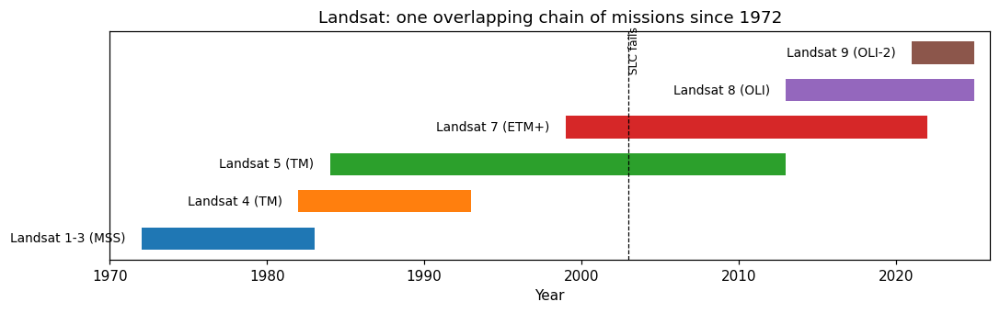

In [6]:
# A timeline makes "longest continuous record" concrete: five missions, one overlapping chain
# from 1972 to today, with the Landsat 7 SLC failure marked where it starts degrading data.
spans = [("Landsat 1-3 (MSS)", 1972, 1983), ("Landsat 4 (TM)", 1982, 1993),
        ("Landsat 5 (TM)", 1984, 2013), ("Landsat 7 (ETM+)", 1999, 2022),
        ("Landsat 8 (OLI)", 2013, 2025), ("Landsat 9 (OLI-2)", 2021, 2025)]
fig, ax = plt.subplots(figsize=(10, 3.2))  # one panel
for i, (name, start, end) in enumerate(spans):  # every mission
    ax.barh(i, end - start, left=start, height=0.6, color=f"C{i % 6}")  # a bar from launch to end of operations
    ax.text(start - 1, i, name, ha="right", va="center", fontsize=9)  # the mission name to the left
ax.axvline(2003, color="k", ls="--", lw=0.8)  # the year Landsat 7's scan-line corrector failed
ax.text(2003, len(spans) - 0.3, " SLC fails", fontsize=8, rotation=90, va="top")  # label it
# labels and title
ax.set(yticks=[], xlabel="Year", title="Landsat: one overlapping chain of missions since 1972")
ax.set_xlim(1970, 2026)  # years shown
plt.tight_layout(); plt.show()  # arrange and draw

*Landsat 7's scan-line corrector failed in 2003, leaving wedge-shaped gaps in later images.

Band *numbers* differ between sensors: red is band 3 on TM/ETM+ but band 4 on OLI. `geolattice.rsense`
hides this by mapping canonical names (`red`, `nir`, `swir16`) to each sensor's bands.


In [7]:
rows = []  # one row per canonical band
for canon in ["blue", "green", "red", "nir", "swir16", "swir22", "thermal", "qa"]:  # the bands to compare
    # file band name for TM/ETM+ and for OLI, and the STAC key
    rows.append((canon, landsat.BANDS_TM.get(canon, ("n/a",))[-1], landsat.BANDS.get(canon, ("n/a",))[-1],
                 landsat.BANDS.get(canon, ("n/a",))[0]))
pd.DataFrame(rows, columns=["Canonical", "TM/ETM+ (C2 file)", "OLI (C2 file)", "STAC asset key"])  # as a table

,Canonical,TM/ETM+ (C2 file),OLI (C2 file),STAC asset key
0,blue,SR_B1,SR_B2,blue
1,green,SR_B2,SR_B3,green
2,red,SR_B3,SR_B4,red
3,nir,SR_B4,SR_B5,nir08
4,swir16,SR_B5,SR_B6,swir16
5,swir22,SR_B7,SR_B7,swir22
6,thermal,ST_B6,ST_B10,lwir11
7,qa,QA_PIXEL,QA_PIXEL,qa_pixel


**Collection 2** (2020) reprocessed the whole archive with improved geolocation. Each scene
comes at two levels:

- **Level-1 (L1TP)**: calibrated top-of-atmosphere DN, with coefficients in the `MTL` file.
  MSS (1972-1993) only exists at Level-1, there was never an atmospheric-correction model
  developed for it.
- **Level-2 (L2SP)**: atmospherically corrected **surface reflectance** (`SR_B*`) and
  **surface temperature** (`ST_B10`), plus `QA_PIXEL`. Use Level-2 for almost all analyses.

Scene identifiers encode everything you need:


In [8]:
def parse_landsat_id(pid):  # decode a Landsat product ID
    p = pid.split("_")  # split it at the underscores
    # sensor, mission, level, path/row, dates, collection and tier
    return {"sensor": {"LC": "OLI/TIRS", "LE": "ETM+", "LT": "TM", "LM": "MSS"}[p[0][:2]], "mission": int(p[0][2:]),
            "level": p[1], "path": int(p[2][:3]), "row": int(p[2][3:]),
            "acquired": pd.Timestamp(p[3]).date(), "processed": pd.Timestamp(p[4]).date(),
            "collection": int(p[5]), "tier": p[6]}

pd.Series(parse_landsat_id("LC09_L2SP_039035_20240708_20240710_02_T1"))  # decode one Landsat 9 ID

sensor          OLI/TIRS
mission                9
level               L2SP
path                  39
row                   35
acquired      2024-07-08
processed     2024-07-10
collection             2
tier                  T1
dtype: object

## Loading Landsat data

`rs.optical.load_landsat` searches Planetary Computer and loads bands lazily, already scaled
and cloud-masked, no files to manage, needs the optional `odc-stac` package. The rest of this
notebook instead uses `geolattice.rsense.get_images`, which downloads full-resolution (30 m) bands
as AOI-clipped GeoTIFFs: real files on disk, the same download route the MODIS notebook (07_02_03) and this
notebook's download sections use. We pick a real, nearly cloud-free Landsat 9 scene over Las Vegas
(path 39, row 35, 8 July 2024).


In [9]:
AOI = (-115.4, 35.95, -114.85, 36.35)  # Las Vegas AOI (lon/lat)

if ONLINE:  # only when online
    try:
        # lazily load Landsat 9 scenes of early July 2024
        lv = rs.optical.load_landsat(AOI, ("2024-07-01", "2024-07-15"), platforms=("landsat-9",), max_cloud=10)
        print(lv)  # show the Dataset
    except ImportError as exc:
        print("load_landsat needs an optional dependency:", exc)  # an optional dependency is missing
else:
    print("Offline: skipping the lazy-load demo. The get_images download below needs internet too.")  # offline

load_landsat needs an optional dependency: odc.stac is required; install with `pip install geolattice[rsense-access]`


### One scene from each mission

The same Las Vegas box, seen by Landsat 1, 3, 4, 5, 7, 8 and 9. Landsat 1 and 3 carry MSS only, so they come from Collection 2 Level-1 (top of atmosphere, about 60 m, green, red and near infrared, no blue band). Landsat 4, 5, 7, 8 and 9 are Collection 2 Level-2 surface reflectance at 30 m (TM, ETM+ and OLI). Each download is one clear summer scene that covers the whole box: WRS-1 path 42 / row 35 for MSS, and WRS-2 path 39 / row 35 from Landsat 4 onward. Landsat 7 is from August 2000, before the scan-line corrector failed.


In [10]:
# One clear summer scene per mission, clipped to the AOI above.
# MSS (Landsat 1 and 3) is Level-1; TM, ETM+ and OLI are Level-2.
MISSIONS = [
    ("Landsat 1 MSS", "1974-07-29", "LM01_L1TP_042035_19740729_02_T2",
     "landsat-c2-l1", ["landsat-1"], ["red", "green", "nir08"], ["nir08", "red", "green"]),
    ("Landsat 3 MSS", "1978-06-20", "LM03_L1TP_042035_19780620_02_T2",
     "landsat-c2-l1", ["landsat-3"], ["red", "green", "nir08"], ["nir08", "red", "green"]),
    ("Landsat 4 TM", "1992-06-14", "LT04_L2SP_039035_19920614_02_T1",
     "landsat-c2-l2", ["landsat-4"], ["blue", "green", "red", "nir"], ["red", "green", "blue"]),
    ("Landsat 5 TM", "2006-06-29", "LT05_L2SP_039035_20060629_02_T1",
     "landsat-c2-l2", ["landsat-5"], ["blue", "green", "red", "nir"], ["red", "green", "blue"]),
    ("Landsat 7 ETM+", "2000-08-07", "LE07_L2SP_039035_20000807_02_T1",
     "landsat-c2-l2", ["landsat-7"], ["blue", "green", "red", "nir"], ["red", "green", "blue"]),
    ("Landsat 8 OLI", "2017-06-27", "LC08_L2SP_039035_20170627_02_T1",
     "landsat-c2-l2", ["landsat-8"], ["blue", "green", "red", "nir"], ["red", "green", "blue"]),
    ("Landsat 9 OLI-2", "2024-07-08", "LC09_L2SP_039035_20240708_02_T1",
     "landsat-c2-l2", ["landsat-9"], ["blue", "green", "red", "nir"], ["red", "green", "blue"]),
]
MISSION_OUT = DATA / "landsat_missions"  # output folder for the mission samples

# True when every band of every mission scene is already on the local drive
have_all = all((MISSION_OUT / m[2] / f"{b}.tif").exists() for m in MISSIONS for b in m[5])

if have_all:  # downloaded before
    print("Reading the mission scenes already downloaded under", MISSION_OUT)  # use the local drive
elif ONLINE:  # not on disk yet: download when online
    for label, day, sid, collection, platforms, bands, _rgb in MISSIONS:  # every mission sample
        found = search_images(bbox=AOI, dates=(day, day), source="planetary",  # find the scene on that day
                              collection=collection, platforms=platforms, limit=10, quiet=True)
        # download only the needed bands, clipped to the AOI
        got = get_images(MISSION_OUT, search=found, ids=[sid], bands=bands, mode="clip", quiet=True)
        # report the download
        print(f"{label:16} {sid} -> {len(got.scenes)} scene, {len(got.failures)} failures")
else:
    print("Offline: skipping the mission downloads.")  # offline

1 scene(s), 3 band file(s) to fetch


bands: 100%|██████████| 3/3 [00:01<00:00,  2.00it/s]


Landsat 1 MSS    LM01_L1TP_042035_19740729_02_T2 -> 1 scene, 0 failures
1 scene(s), 3 band file(s) to fetch


bands: 100%|██████████| 3/3 [00:01<00:00,  2.12it/s]


Landsat 3 MSS    LM03_L1TP_042035_19780620_02_T2 -> 1 scene, 0 failures
1 scene(s), 4 band file(s) to fetch


bands: 100%|██████████| 4/4 [00:03<00:00,  1.29it/s]


... (5 outputs left out)

bands: 100%|██████████| 4/4 [00:04<00:00,  1.20s/it]


Landsat 8 OLI    LC08_L2SP_039035_20170627_02_T1 -> 1 scene, 0 failures
1 scene(s), 4 band file(s) to fetch


bands: 100%|██████████| 4/4 [00:03<00:00,  1.12it/s]

Landsat 9 OLI-2  LC09_L2SP_039035_20240708_02_T1 -> 1 scene, 0 failures


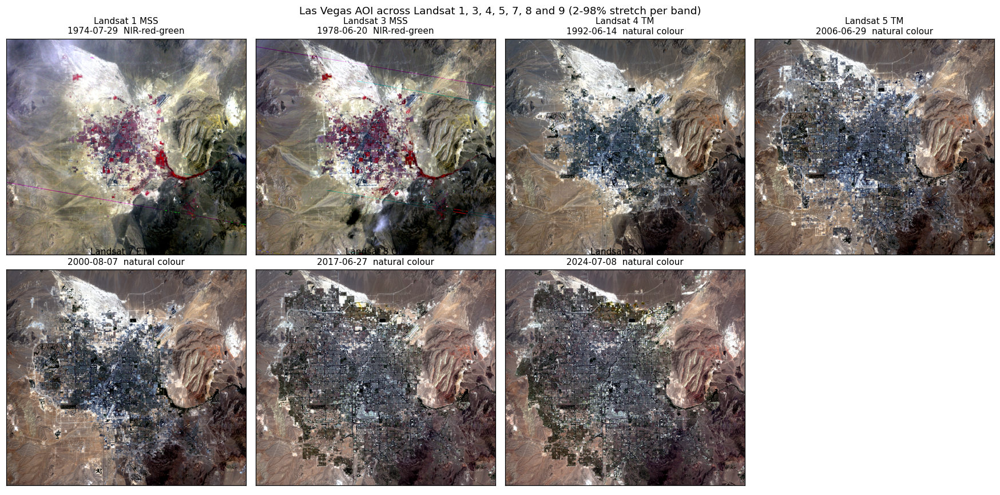

In [11]:
from geolattice.rsense.viz.stretch import rgb as make_rgb  # build a stretched RGB image from a Dataset

fig, axes = plt.subplots(2, 4, figsize=(16, 8))  # 2 x 4 panels
for ax, (label, day, sid, *_rest, rgb_bands) in zip(axes.ravel(), MISSIONS):  # one panel per mission
    folder = MISSION_OUT / sid  # folder of its scene
    data = {}  # band name -> array
    for name in rgb_bands:  # the three display bands
        da = rs.read(folder / f"{name}.tif", masked=False).squeeze("band", drop=True)  # read the band
        data[name] = da.where(da > 0)          # 0 is the fill value on both Level-1 and Level-2
    img = make_rgb(xr.Dataset(data), rgb_bands)  # stretched RGB image
    ax.imshow(np.nan_to_num(img.values), origin="upper")  # show it
    kind = "NIR-red-green" if rgb_bands[0].startswith("nir") else "natural colour"  # false or natural colour
    ax.set_title(f"{label}\n{day}  {kind}", fontsize=10)  # title
    ax.set_xticks([]); ax.set_yticks([])  # no ticks
axes.ravel()[-1].axis("off")  # the eighth panel is empty
fig.suptitle("Las Vegas AOI across Landsat 1, 3, 4, 5, 7, 8 and 9 (2-98% stretch per band)")  # overall title
plt.tight_layout(); plt.show()  # arrange and draw

In [12]:
# Search for the scene by id so the rest of the notebook reproducibly uses the exact same
# acquisition, then download its reflective and thermal bands plus QA_PIXEL at native 30 m,
# clipped to the AOI.
SCENE_ID = "LC09_L2SP_039035_20240708_02_T1"
# Landsat 9 bands to download
LS_BANDS = ["coastal", "blue", "green", "red", "nir", "swir16", "swir22", "lwir11", "qa_pixel"]

LS_OUT = DATA / "landsat9_vegas_20240708"  # folder for the Landsat 9 scene

# True when every band of the scene is already on the local drive
if all((LS_OUT / SCENE_ID / f"{b}.tif").exists() for b in LS_BANDS):
    print("Reading the Landsat 9 scene already downloaded under", LS_OUT)  # use the local drive
else:  # not on disk yet: search and download
    # find the 8 July 2024 scene
    found = search_images(bbox=AOI, dates=("2024-07-08", "2024-07-08"), source="planetary",
                          collection="landsat-c2-l2", platforms=["landsat-9"], limit=5, quiet=True)
    # download those bands, clipped to the AOI
    saved = get_images(LS_OUT, search=found, ids=[SCENE_ID],
                       bands=LS_BANDS, mode="clip", quiet=True)
    print(saved)  # summary of the download

1 scene(s), 9 band file(s) to fetch


bands: 100%|██████████| 9/9 [00:05<00:00,  1.67it/s]

ImageResult(planetary/landsat-c2-l2, 1 scenes, 12 files, 0 failures, out=Tutorials/notebooks/09_remote_sensing/09_02_optical/data/landsat9_vegas_20240708)


In [13]:
# Assemble the raw digital numbers into one Dataset. These are the real stored DN values —
# The scale-factors section converts them to reflectance and Kelvin, instead of faking a round trip.
scene_dir = LS_OUT / SCENE_ID  # the scene folder on the local drive
# every band as raw digital numbers
ls_dn = xr.Dataset({b: rs.read(scene_dir / f"{b}.tif", masked=False).squeeze("band", drop=True)
                    for b in LS_BANDS})
ls_dn = ls_dn.rio.write_crs(ls_dn["red"].rio.crs)  # attach the CRS
ls_dn.attrs["pyrsense:sensor"] = "landsat"  # record the sensor
# size, pixel size and CRS
print(f"{ls_dn.rio.width} x {ls_dn.rio.height} pixels at {ls_dn.rio.resolution()[0]:.0f} m, CRS {ls_dn.rio.crs}")
ls_dn  # show the Dataset

1679 x 1512 pixels at 30 m, CRS EPSG:32611


<xarray.Dataset> Size: 46MB
Dimensions:      (x: 1679, y: 1512)
Coordinates:
  * x            (x) float64 13kB 6.436e+05 6.436e+05 ... 6.939e+05 6.939e+05
  * y            (y) float64 12kB 4.025e+06 4.025e+06 ... 3.98e+06 3.98e+06
    spatial_ref  int64 8B 0
Data variables:
    coastal      (y, x) uint16 5MB ...
    blue         (y, x) uint16 5MB ...
    green        (y, x) uint16 5MB ...
    red          (y, x) uint16 5MB ...
    nir          (y, x) uint16 5MB ...
    swir16       (y, x) uint16 5MB ...
    swir22       (y, x) uint16 5MB ...
    lwir11       (y, x) uint16 5MB ...
    qa_pixel     (y, x) uint16 5MB ...
Attributes:
    pyrsense:sensor:  landsat

## Scale factors

Landsat Collection 2 Level-2 data is distributed as unsigned 16-bit digital numbers (DNs). 
These DNs require scaling to retrieve physical values:

- For surface reflectance bands (e.g., blue, green, red, NIR, SWIR), the reflectance is calculated as:
    - **Reflectance = DN × 0.0000275 − 0.2**
    - Valid range: DN values 7,273 to 43,636 map to surface reflectance values of 0 to 1.
- For the surface temperature band (thermal infrared, typically B10), the conversion to Kelvin is:
    - **Surface temperature (K) = DN × 0.00341802 + 149.0**
- A DN value of 0 indicates a fill value (nodata; these pixels should be ignored).

The scaling function `rs.optical.scale` automatically detects the relevant bands within the dataset.
It applies the appropriate equation to each band, converting raw DNs to meaningful physical units 
(reflectance, temperature), while keeping non-spectral bands like `qa_pixel` unmodified. 
In this notebook, we use it to scale the real (unmodified) DNs downloaded in the *Loading Landsat data* section to obtain
correctly calibrated surface reflectance and temperature data.


In [14]:
# This block scales the raw digital number (DN) values for each physical band in the Landsat scene
# to meaningful physical units (reflectance or temperature), then summarizes the values for a sample pixel.

# 1. Convert the DN values in 'ls_dn' to scaled reflectance and temperature values, producing a new xarray Dataset.
ls = rs.optical.scale(ls_dn, sensor="landsat")

# 2. Choose a specific pixel position (y=700, x=800) in the image for sampling.
px = dict(y=700, x=800)

# 3. Select all bands except 'qa_pixel' (i.e., only the bands with physical meaning).
phys_bands = [b for b in LS_BANDS if b != "qa_pixel"]

# 4. For each physical band, extract at that pixel:
#    - The original DN value (integer read directly from the file)
#    - The scaled value (rounded to 4 decimals), in physical units
#    - The units (from array metadata; reflectance or Kelvin)
#    These are assembled into a pandas DataFrame for easy inspection.
pd.DataFrame({
    "stored DN": [int(ls_dn[b].isel(px)) for b in phys_bands],
    "scaled": [round(float(ls[b].isel(px)), 4) for b in phys_bands],
    "units": [ls[b].attrs.get("units") for b in phys_bands],
}, index=phys_bands)

,stored DN,scaled,units
coastal,11063,0.1042,reflectance
blue,11880,0.1267,reflectance
green,14641,0.2026,reflectance
red,15954,0.2387,reflectance
nir,17900,0.2922,reflectance
swir16,19533,0.3372,reflectance
swir22,18187,0.3001,reflectance
lwir11,52759,329.3313,K


Atmospheric correction can push very dark surfaces (deep water, shadow) slightly below zero.
Negative values make ratio indices explode (e.g. NDVI = −500 when NIR ≈ −0.001), so we clip
reflectance to a small positive floor before computing indices.


In [15]:
# Count and display the number of negative reflectance pixels for each physical band except 'lwir11' (thermal IR).
# Negative reflectance values can occur due to atmospheric correction artifacts.
neg = {b: int((ls[b] < 0).sum()) for b in phys_bands if b != "lwir11"}
# Only print bands where negative pixels exist.
print("Negative reflectance pixels (real scene):", {b: n for b, n in neg.items() if n})

# Clip all reflectance bands to a minimum value of 1e-4 and maximum of 1.0,
# to avoid extreme values in index calculations. The thermal band is left unclipped.
ls = ls.clip(min=1e-4, max=1.0)
ls["lwir11"] = rs.optical.scale(ls_dn, sensor="landsat")["lwir11"]   # Restore thermal band to original, in Kelvin (K).

# Set a sensor attribute for documentation and future reference.
ls.attrs["pyrsense:sensor"] = "landsat"

# Display the constants used to convert thermal band B10 (Landsat 9) DN values to Kelvin,
# which can be useful for reference or further processing.
print(f"Landsat 9 B10 thermal constants (K1, K2): {landsat.THERMAL_K['landsat-9']['B10']}")

Negative reflectance pixels (real scene): {'coastal': 5962, 'blue': 1915, 'green': 22, 'red': 23, 'nir': 57, 'swir16': 8, 'swir22': 2}
Landsat 9 B10 thermal constants (K1, K2): (799.0284, 1329.2405)


## Decoding `QA_PIXEL`

`QA_PIXEL` packs per-pixel flags into 16 bits (CFMask algorithm):

| Bit | Flag | Bits | Confidence (00 none, 01 low, 10 medium, 11 high) |
|---|---|---|---|
| 0 | Fill | 8-9 | Cloud |
| 1 | Dilated cloud | 10-11 | Cloud shadow |
| 2 | Cirrus | 12-13 | Snow/ice |
| 3 | Cloud | 14-15 | Cirrus |
| 4 | Cloud shadow | | |
| 5 | Snow | | |
| 6 | Clear | | |
| 7 | Water | | |

A handful of values account for most pixels in real scenes. Let's decode them, including the
ones that actually occur in our downloaded scene.


In [16]:
# This block decodes the most common QA_PIXEL bit patterns found in Landsat scenes and summarizes
# which quality flags (cloud, shadow, water, etc.) are set for those values. It also flags which codes
# are actually present in our particular scene.

# 1. Prepare an array of typical QA_PIXEL values observed in real scenes.
codes = xr.DataArray(
    np.array([1, 21824, 21952, 22080, 22280, 23888, 30048, 54596, 55052], dtype="uint16"),
    dims="value"
)

# 2. Decode the individual boolean flags (fill, cloud, shadow, snow, water, etc.) using their bit positions.
flags = {
    name: rs.optical.decode_bits(codes, bit).values
    for name, bit in landsat.QA_BITS.items()
}

# 3. Decode the quality confidence for selected features (cloud, shadow, snow, cirrus).
# These are stored as 2 bits each; decode_bits(..., 2) decodes 2-bit fields.
conf = {
    f"{n}_conf": rs.optical.decode_bits(codes, b, 2).values
    for n, b in [("cloud", 8), ("shadow", 10), ("snow", 12), ("cirrus", 14)]
}

# 4. Compile the information into a single DataFrame.
qa_table = pd.DataFrame({**flags, **conf}, index=codes.values)

# 5. For each code, indicate if it would be marked as "usable" (clear land/water) by the default mask.
qa_table["usable (default mask)"] = rs.optical.landsat_qa_mask(codes).values

# 6. Check which codes from the list are actually present in the current scene.
real_codes, real_counts = np.unique(ls_dn["qa_pixel"].values, return_counts=True)
# does the code occur in this scene?
qa_table["present in our scene"] = [int(c) in real_codes for c in codes.values]

# 7. Display the summary DataFrame.
qa_table

,fill,dilated_cloud,cirrus,cloud,shadow,snow,clear,water,cloud_conf,shadow_conf,snow_conf,cirrus_conf,usable (default mask),present in our scene
1,1,0,0,0,0,0,0,0,0,0,0,0,False,False
21824,0,0,0,0,0,0,1,0,1,1,1,1,True,True
21952,0,0,0,0,0,0,1,1,1,1,1,1,True,True
22080,0,0,0,0,0,0,1,0,2,1,1,1,True,False
22280,0,0,0,1,0,0,0,0,3,1,1,1,False,False
23888,0,0,0,0,1,0,1,0,1,3,1,1,False,False
30048,0,0,0,0,0,1,1,0,1,1,3,1,True,False
54596,0,0,1,0,0,0,1,0,1,1,1,3,False,True
55052,0,0,1,1,0,0,0,0,3,1,1,3,False,False


So 21824 is clear land, 21952 clear water, 22280 high-confidence cloud, 23888 cloud shadow,
30048 snow, and 54596/55052 are cirrus/cloud with dilation. Our scene is a near-cloudless
summer desert, so only clear-land and clear-water codes actually occur (check the table above);
the rest are here to show what a cloudier scene decodes to. The default `landsat_qa_mask` keeps
clear land and water; pass `snow=True` or `water=True` to drop those too.


## Colour composites

Assigning different bands to red, green and blue highlights different surface properties.
`rs.viz.plot_rgb` has presets and applies a 2-98 % percentile stretch per band.


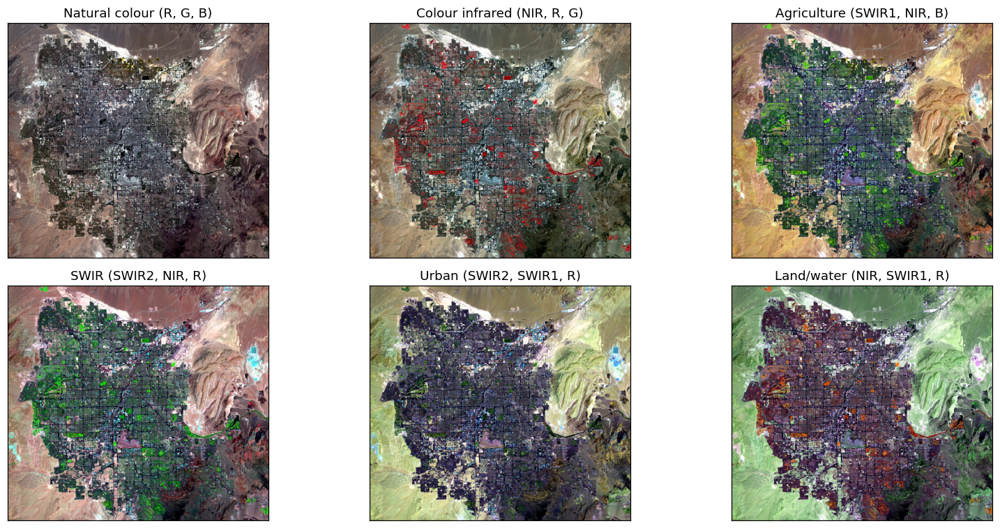

In [17]:
# Define a dictionary of RGB composite presets, mapping internal preset names
# to readable descriptions showing which bands will be mapped to RGB.
presets = {
    "true_color": "Natural colour (R, G, B)",
    "false_color": "Colour infrared (NIR, R, G)",
    "agriculture": "Agriculture (SWIR1, NIR, B)",
    "swir": "SWIR (SWIR2, NIR, R)",
    "urban": "Urban (SWIR2, SWIR1, R)",
    "water": "Land/water (NIR, SWIR1, R)",
}

# Create a 2x3 grid of subplots to display all six composites side by side.
fig, axes = plt.subplots(2, 3, figsize=(15, 7))

# Loop over both the axes and the preset-composite pairs.
# For each subplot, plot the Landsat RGB composite image using the current preset,
# set the subplot title to the readable description,
# and remove axis ticks for a cleaner display.
for ax, (preset_name, title) in zip(axes.ravel(), presets.items()):
    rs.viz.plot_rgb(ls, preset_name, ax=ax, title=title)  # the composite with this preset
    ax.set_xticks([])  # no x ticks
    ax.set_yticks([])  # no y ticks

# Adjust layout so plots do not overlap and display the figure.
plt.tight_layout()
plt.show()  # draw

Irrigated parks and golf courses glow red in colour infrared; Lake Mead is black in the
land/water composite because water absorbs NIR and SWIR; the urban composite separates
roofs and pavement (purple-grey) from desert soils (tan).


## Spectral indices

The `geolattice.rsense` registry holds over 100 indices with formulas, references and domains. Indices
use canonical band names, so the same call works for Landsat, Sentinel-2, MODIS or HLS.


In [18]:
catalog = rs.optical.list_indices()  # every spectral index GeoLattice knows
print(len(catalog), "indices registered")  # how many
catalog.domain.value_counts().to_frame("count").T  # count per domain (vegetation, water, urban, ...)

121 indices registered


domain,vegetation,water,rededge,rgb,burn,urban,soil,snow,other
count,41,20,18,14,9,7,5,4,3


In [19]:
# a few common indices
catalog[catalog.name.isin(["NDVI", "EVI", "SAVI", "MNDWI", "NDBI", "NBR", "BSI", "NDMI"])]

,name,long_name,bands,domain,reference
0,NDVI,Normalized Difference Vegetation Index,"nir, red",vegetation,Rouse et al. 1974
1,EVI,Enhanced Vegetation Index,"nir, red, blue",vegetation,Huete et al. 2002
3,SAVI,Soil-Adjusted Vegetation Index,"nir, red",vegetation,Huete 1988
14,MNDWI,Modified NDWI,"green, swir16",water,Xu 2006
19,NDMI,Normalized Difference Moisture Index,"nir, swir16",water,Gao 1996
20,NBR,Normalized Burn Ratio,"nir, swir22",burn,Key & Benson 2006
22,NDBI,Normalized Difference Built-up Index,"swir16, nir",urban,Zha et al. 2003
23,BSI,Bare Soil Index,"swir16, red, nir, blue",soil,Rikimaru et al. 2002


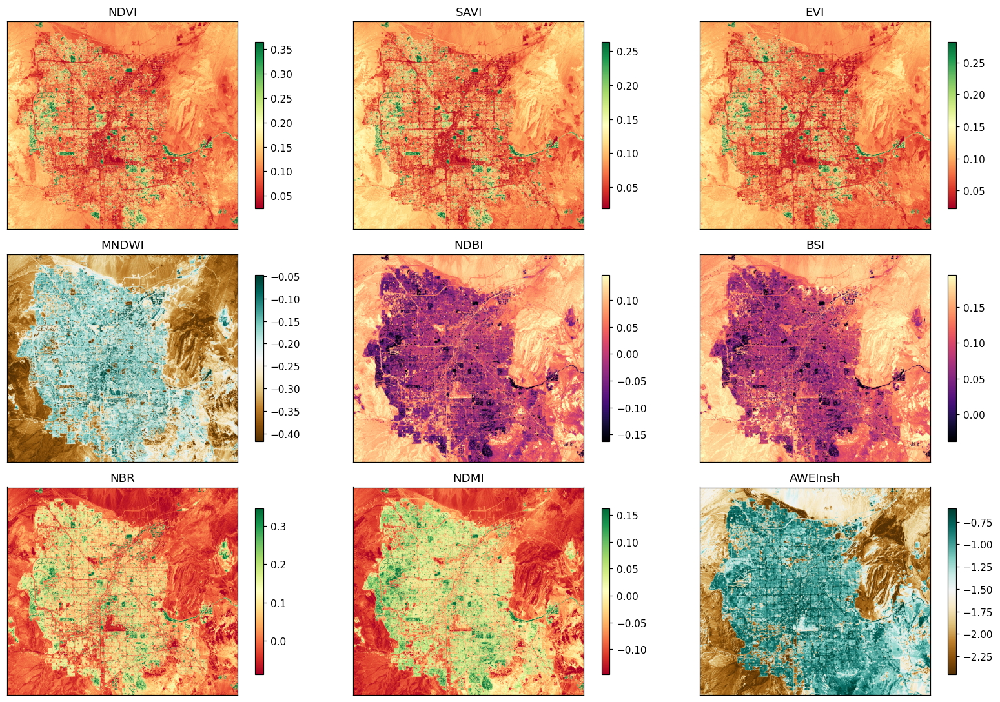

In [20]:
# Define a list of spectral index names to compute on the Landsat image
names = ["NDVI", "SAVI", "EVI", "MNDWI", "NDBI", "BSI", "NBR", "NDMI", "AWEInsh"]

# Compute all the requested indices, resulting in a multi-band result (one band per index)
vi = ls.rs.index(names)

# Assign specific color maps to certain indices for visualization clarity; other indices use a default colormap
cmaps = {"MNDWI": "BrBG", "AWEInsh": "BrBG", "NDBI": "magma", "BSI": "magma"}

# Create a 3x3 grid of subplots with a specified figure size to organize the index plots
fig, axes = plt.subplots(3, 3, figsize=(15, 10))

# Loop over each subplot and index name simultaneously
for ax, n in zip(axes.ravel(), names):
    # Plot the computed index raster on the current axis, using the proper colormap and setting the title
    rs.viz.plot_raster(vi[n], ax=ax, cmap=cmaps.get(n, "RdYlGn"), title=n)
    # Remove axis tick labels for visual cleanliness
    ax.set_xticks([]); ax.set_yticks([])

# Adjust subplot layout to avoid overlap and display the collection of index maps
plt.tight_layout(); plt.show()

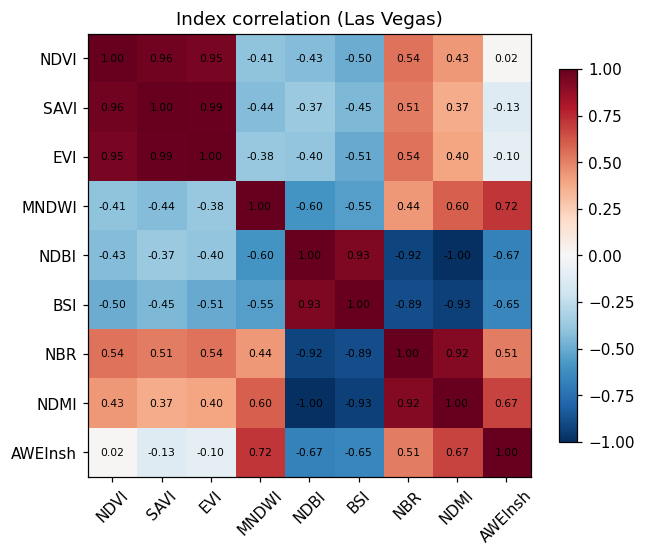

In [21]:
# The following code computes and visualizes the correlation between different spectral indices.
# Since many indices capture similar information, analyzing their correlations can reveal redundancy.
# 
# 1. Take a DataFrame of all indices, remove rows with missing values, and randomly sample 20,000 pixels.
# 2. Calculate the correlation matrix among the chosen indices.
# 3. Create a heatmap plot of the correlation matrix, using a diverging color map ("RdBu_r") for positive and negative correlations.
# 4. Set the tick labels to the index names and rotate x-axis labels for clarity.
# 5. Annotate each cell of the heatmap with the correlation coefficient (rounded to two decimals).
# 6. Add a colorbar for reference and a descriptive plot title, then display the plot.

sample = vi.to_dataframe()[names].dropna().sample(20000, random_state=0)  # Random set of 20,000 valid pixels
corr = sample.corr()  # Correlation matrix of the indices
fig, ax = plt.subplots(figsize=(6.5, 5.5))  # one panel
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)  # Heatmap of correlations (red: negative, blue: positive)
ax.set_xticks(range(len(names)), names, rotation=45)  # index names on the x axis
ax.set_yticks(range(len(names)), names)  # and on the y axis
for i in range(len(names)):  # every row ...
    for j in range(len(names)):  # ... and column
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)  # Annotate with correlation value
plt.colorbar(im, shrink=0.8)  # colour bar
ax.set_title("Index correlation (Las Vegas)")  # title
plt.show()  # draw

In this arid scene NDVI, SAVI and EVI are almost interchangeable, while NDBI is close to the
negative of NDMI (both use NIR and SWIR1). Choose indices that add *different* information.

You can add your own index; it becomes available everywhere, including `.rs.index`:


In [22]:
# Register a custom vegetation index named "NDVIre_like" which is a toy example of a SWIR-adjusted NDVI.
# The formula incorporates the NIR (near-infrared), red, and SWIR2 (shortwave infrared 2) spectral bands:
# (NIR - Red - 0.5 * SWIR2) / (NIR + Red + 0.5 * SWIR2).
# This new index is given a domain of "vegetation" and a reference comment "Tutorial example".
# Setting overwrite=True allows it to be re-registered if already present.
rs.optical.register_index(
    "NDVIre_like",                          # short name for the index
    "Toy SWIR-adjusted NDVI",               # human-friendly description
    ["nir", "red", "swir22"],               # required bands
    lambda nir, red, swir22: (nir - red - 0.5 * swir22) / (nir + red + 0.5 * swir22),  # computation
    domain="vegetation",
    reference="Tutorial example",
    overwrite=True
)

# Compute and display the mean value of the new index over the Landsat scene.
float(ls.rs.index("NDVIre_like").mean())

-0.10867444425821304

## Validating index-based water and built-up maps

Thresholded indices, such as MNDWI (for mapping water) and combinations like NDBI > 0 & NDVI < 0.2 (for mapping built-up areas), provide simple, rapid classification maps of land cover.
However, these "quick maps" can be misleading if not validated against reliable, independent reference data, since threshold choices may not generalize across regions or conditions.
To assess the accuracy of these index-based classifications, we compare their results with the National Land Cover Database (NLCD) 2021, which serves as ground truth. 
The NLCD data is accessed in the form of a cloud-optimized GeoTIFF directly from the web, and for efficiency, only the section corresponding to the Las Vegas area (the current scene) is downloaded and used for validation.


In [23]:
# This code section validates simple water and built-up area maps based on thresholded spectral indices, 
# by comparing them to reference data from the National Land Cover Database (NLCD).

# 1. Load the NLCD reference data for the same area as the current Landsat scene (las vegas).
nlcd = nlcd_for(ls["red"])

# 2. Define reference masks from NLCD classes: 
#    - water: class 11
#    - built-up: classes 22, 23, 24 (various types of developed/urban land)
water_ref = nlcd.isin([11])
built_ref = nlcd.isin([22, 23, 24])  # reference built-up area: NLCD developed low, medium and high

# 3. Threshold the remotely sensed indices to create binary water and built-up predictions.
#    - For water: Use the MNDWI index, classifying as water where MNDWI > 0 (literature-based threshold).
#      (Otsu's method is mentioned, but avoided here because water is extremely rare in this desert area.)
water = vi["MNDWI"] > 0.0

#    - For built-up: Common rule combines a high NDBI (Normalized Difference Built-up Index) 
#      and a low NDVI (to exclude vegetated/non-urban areas).
built = (vi["NDBI"] > 0) & (vi["NDVI"] < 0.2)

# 4. Restrict evaluation to valid pixels (NLCD value > 0)
valid = nlcd > 0

# 5. For both water and built-up, compare the predictions to the NLCD reference and compute accuracy metrics.
rows = {}
for name, pred, ref in [  # each prediction compared with the reference
    ("Water (MNDWI > 0)", water, water_ref),
    ("Built-up (NDBI > 0 & NDVI < 0.2)", built, built_ref)
]:
    # Compute an accuracy report: overall accuracy, kappa statistic, user's (precision) and producer's (recall) accuracy for the "positive" class.
    r = rs.classify.accuracy_report(ref.values[valid.values], pred.values[valid.values], labels=[False, True])
    pc = r["per_class"].loc[True]  # scores of the "built-up" class
    rows[name] = {  # one row of scores
        "overall accuracy": r["overall_accuracy"],
        "kappa": r["kappa"],
        "user's acc. (class)": pc.users_accuracy,
        "producer's acc. (class)": pc.producers_accuracy
    }

# 6. Print statistics about reference pixels:
print(
    f"Water reference pixels: {int(water_ref.values[valid.values].sum())} of {int(valid.sum())} "
    f"({float(water_ref.values[valid.values].mean()):.2%})"
)

#    Also, print the median NDBI for built-up ("developed") and for shrub/barren desert in the area 
#    (to help explain misclassification results).
print(
    f"Median NDBI: developed: {float(vi['NDBI'].where(built_ref).median()):.3f}, "
    f"shrub/barren desert: {float(vi['NDBI'].where(nlcd.isin([31, 52])).median()):.3f}"
)

# 7. Display accuracy metrics in a DataFrame.
pd.DataFrame(rows).T.round(3)

Water reference pixels: 2378 of 2538648 (0.09%)
Median NDBI: developed: -0.016, shrub/barren desert: 0.096


,overall accuracy,kappa,user's acc. (class),producer's acc. (class)
Water (MNDWI > 0),0.990,0.098,0.054,0.616
Built-up (NDBI > 0 & NDVI < 0.2),0.203,-0.481,0.227,0.394


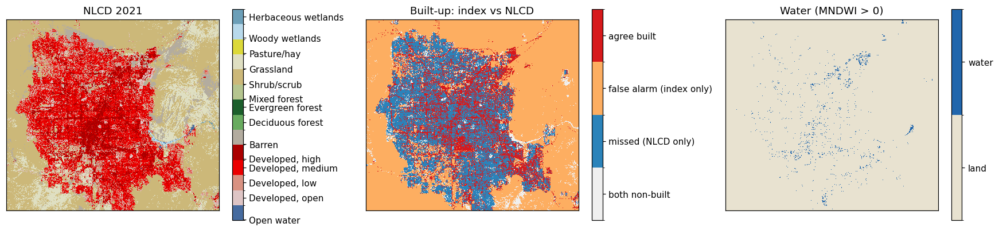

In [24]:
# This block visualizes and compares the land cover reference (NLCD),
# the agreement/disagreement between built-up predictions and the NLCD reference,
# and the remotely sensed water prediction (MNDWI > 0).

# 1. Set up a figure with 3 side-by-side axes.
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# 2. Plot the original NLCD land cover map for the valid pixels.
#    The legend only includes mapped NLCD class codes that actually appear in our subset.
rs.viz.plot_raster(
    nlcd.where(valid),
    ax=axes[0],
    title="NLCD 2021",
    categorical={k: v for k, v in NLCD_CLASSES.items() if k in np.unique(nlcd.values)}
)

# 3. Plot a map showing, pixel by pixel, where the built-up mask and NLCD agree or disagree,
#    for valid pixels only. `agree` codes: 
#    0: both non-built,
#    1: missed (NLCD built-up but not by index), 
#    2: false alarm (index only), 
#    3: agree built.
agree = (built.astype(int) * 2 + built_ref.astype(int)).where(valid)
rs.viz.plot_raster(  # map of the layer
    agree,
    ax=axes[1],
    title="Built-up: index vs NLCD",
    categorical={
        0: ("both non-built", "#f0f0f0"),
        1: ("missed (NLCD only)", "#2b83ba"),
        2: ("false alarm (index only)", "#fdae61"),
        3: ("agree built", "#d7191c")
    }
)

# 4. Plot the predicted water map using MNDWI > 0 as threshold, on valid pixels.
rs.viz.plot_raster(
    water.astype(int).where(valid),
    ax=axes[2],
    title="Water (MNDWI > 0)",
    categorical={
        0: ("land", "#e8e2d0"),
        1: ("water", "#2166ac")
    }
)

# 5. Remove axis ticks for a cleaner look, lay out, and show the plot.
for a in axes:
    a.set_xticks([])  # no x ticks
    a.set_yticks([])  # no y ticks
plt.tight_layout()  # arrange
plt.show()  # draw

Water scores 98.9% overall accuracy, but its kappa is only 0.10 and user's accuracy (precision)
just 5%, open water is under 0.1% of this scene, so even a tiny false-positive *rate* swamps
the true water pixels in absolute terms. Overall accuracy alone is misleading for a rare class;
check precision and kappa too. The built-up rule fails outright (kappa below zero): in this
desert, bare soil has a *higher* NDBI than the city (compare the medians printed above with the
NDBI map in the *Spectral indices* section), so the rule flags much of the desert as built-up while missing most of
the city. NDBI was designed for humid regions where non-urban land is vegetated. This is why
index thresholds, and even standard auto-thresholding methods like Otsu, must be validated
locally; the classification chapter, 07_08 replaces them with a trained classifier.


## Land surface temperature

Thermal sensors measure radiance, which converts to **brightness temperature** (BT) with the
Planck constants K1 and K2. BT assumes a blackbody; real surfaces emit less (emissivity ε < 1),
so the land surface temperature is higher than BT:

$$\mathrm{LST} = \frac{BT}{1 + (\lambda BT / \rho)\ln\varepsilon}, \qquad \rho = hc/k = 14388\ \mu m\,K$$

ε can be estimated from NDVI (Sobrino et al. 2004). Collection 2 `ST_B10` already contains LST
computed this way with ASTER-based emissivity. Let's see how much the emissivity correction
matters across Las Vegas for a uniform 310 K brightness temperature:


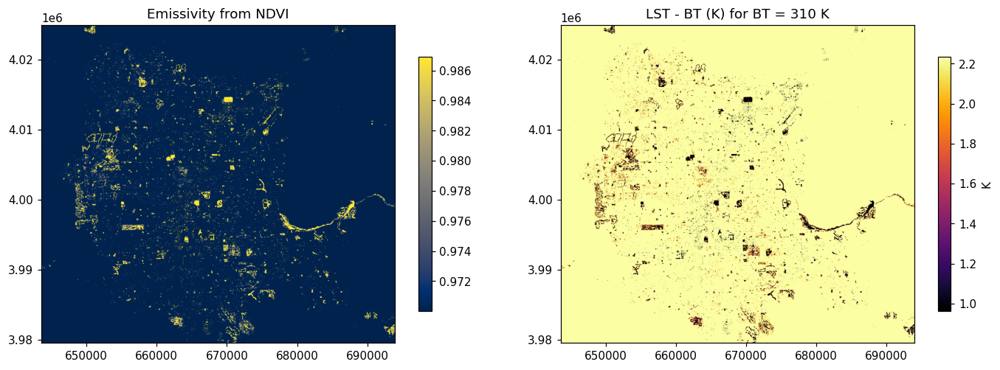

Landsat 9 B10 thermal constants (K1, K2): (799.0284, 1329.2405)


In [25]:
# This code demonstrates how surface emissivity corrections affect Land Surface Temperature (LST) estimates.
# 1. Estimate the land surface emissivity using NDVI, following Sobrino et al. (2004).
emis = rs.optical.emissivity_ndvi(vi["NDVI"])

# 2. Create a synthetic brightness temperature (BT) array, setting all pixels to 310 K.
bt = xr.full_like(vi["NDVI"], 310.0)

# 3. Compute the land surface temperature using the single channel method, accounting for emissivity.
#    The wavelength is set to 10.904 μm, matching Landsat 9 Band 10.
lst = rs.optical.lst_single_channel(bt, emis, wavelength=10.904)

# 4. Plot the estimated emissivity and the difference between LST and BT.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
# emissivity estimated from NDVI
rs.viz.plot_raster(emis, ax=axes[0], cmap="cividis", title="Emissivity from NDVI")
# how much emissivity changes LST for a fixed brightness temperature
rs.viz.plot_raster(lst - bt, ax=axes[1], cmap="inferno", title="LST - BT (K) for BT = 310 K")

plt.tight_layout()  # arrange
plt.show()  # draw

# 5. Print the thermal constants (K1, K2) for Landsat 9 Band 10, which are required for LST calculations from radiance.
print("Landsat 9 B10 thermal constants (K1, K2):", landsat.THERMAL_K["landsat-9"]["B10"])

Ignoring emissivity would underestimate desert surface temperatures by about 2 K and water by
under 1 K. Next we analyse a real LST product: an ECOSTRESS scene over Santa Barbara County on
California's Central Coast, combined with NLCD land cover for the same window.


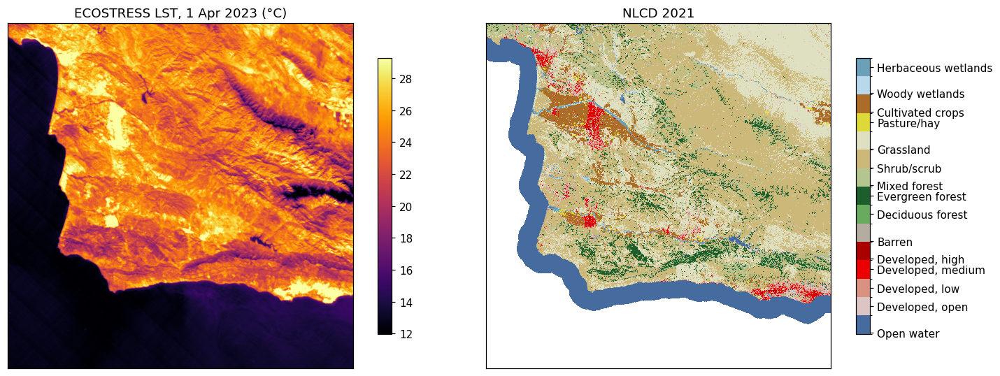

In [26]:
# 1. Read the ECOSTRESS land surface temperature (LST) image and remove the singleton "band" dimension for a simplified 2D array.
eco = rs.read(fetch("ecostress_lst.tif")).squeeze("band", drop=True)

# 2. Convert the LST data from Kelvin to Celsius, renaming the variable accordingly for clarity.
eco_c = (eco - 273.15).rename("LST (°C)")

# 3. Load the NLCD (National Land Cover Database) land cover classification corresponding to the spatial extent of the ECOSTRESS data.
lc_eco = nlcd_for(eco, name="nlcd_ecostress")

# 4. Set up a side-by-side plot with two subplots.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 5a. Display the ECOSTRESS LST (in Celsius) in the first subplot using the "inferno" colormap.
rs.viz.plot_raster(eco_c, ax=axes[0], cmap="inferno", title="ECOSTRESS LST, 1 Apr 2023 (°C)")

# 5b. Display the land cover classification in the second subplot.
#     Only show categories that are present in the data, using their categorical labels.
rs.viz.plot_raster(
    lc_eco.where(lc_eco > 0),
    ax=axes[1],
    title="NLCD 2021",
    categorical={k: v for k, v in NLCD_CLASSES.items() if k in np.unique(lc_eco.values)}
)

# 6. Remove axis ticks for a cleaner presentation.
for a in axes:
    a.set_xticks([])  # no x ticks
    a.set_yticks([])  # no y ticks

# 7. Adjust the layout so plots don't overlap and show the final result.
plt.tight_layout()
plt.show()  # draw

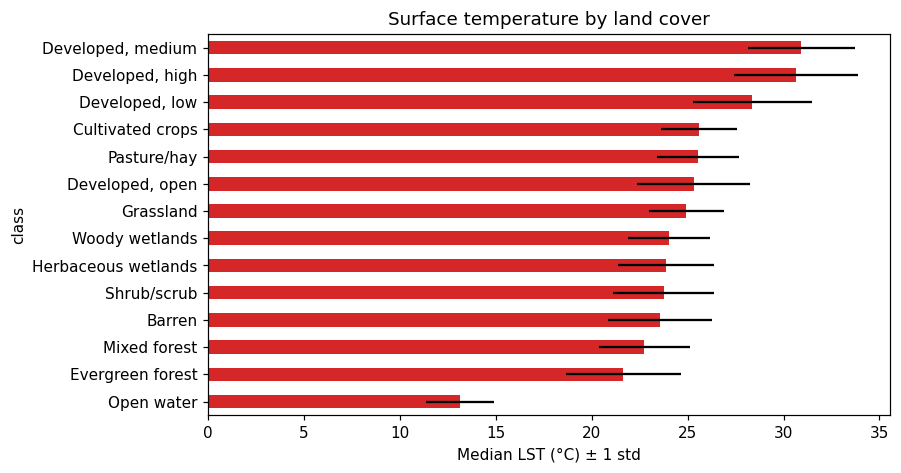

Developed (medium/high) 30.9 °C vs forest/agriculture 23.2 °C -> difference 7.7 °C


In [27]:
# 1. Flatten the ECOSTRESS LST and NLCD arrays and create a DataFrame with these values.
#    Rows with missing (NaN) values are dropped.
df = pd.DataFrame({
    "lst": eco_c.values.ravel(),    # Land Surface Temperature values (in °C)
    "code": lc_eco.values.ravel()   # Land cover code values
}).dropna()

# 2. Remove rows where the land cover code is not positive (e.g., background or unclassified).
df = df[df.code > 0]

# 3. Create a new column mapping each land cover code to its class name.
#    NLCD_CLASSES[c][0] gives the human-readable class label.
df["class"] = df.code.map(lambda c: NLCD_CLASSES[c][0])

# 4. Calculate summary statistics for LST, grouped by land cover class: 
#    - count: number of pixels
#    - median: median LST for the class
#    - std: standard deviation of LST for the class
#    Keep only classes with at least 2,000 pixels, then sort by median LST.
stats = df.groupby("class")["lst"].agg(["count", "median", "std"]).query("count > 2000")
stats = stats.sort_values("median")  # coolest classes first

# 5. Create a horizontal bar plot of the median LST (with standard deviation as error bars)
#    for each land cover class.
ax = stats["median"].plot(
    kind="barh",
    xerr=stats["std"],
    figsize=(8, 4.5),
    color="C3"
)
ax.set(xlabel="Median LST (°C) ± 1 std", title="Surface temperature by land cover")  # labels and title
plt.show()  # draw

# 6. Compare the median surface temperature for two groups:
#    - Developed (medium/high intensity): NLCD codes 23, 24
#    - Forest and agriculture: NLCD codes 41, 42, 43 (forest), 81, 82 (agriculture)
#    Print their median LST and the difference.
dev = df[df.code.isin([23, 24])].lst.median()
veg = df[df.code.isin([41, 42, 43, 81, 82])].lst.median()  # median LST of forest and agriculture
# urban heat island: the difference
print(f"Developed (medium/high) {dev:.1f} °C vs forest/agriculture {veg:.1f} °C -> difference {dev - veg:.1f} °C")

On this spring afternoon developed land is the hottest class, several degrees warmer than
cropland, shrubland and forest, and the ocean is coolest: a clear surface urban heat island.
Compare this with Las Vegas, where the desert around the city can be as hot as, or hotter than,
the irrigated city itself.


## Summary, exercises and references

**Key ideas**

- Landsat offers 30 m imagery back to 1984 (TM) and 1972 (MSS), free and consistently calibrated.
- Use Collection 2 Level-2: apply `DN × 0.0000275 − 0.2` for reflectance and decode `QA_PIXEL`.
- Band numbers differ between sensors; canonical names make code sensor-independent.
- Indices are fast but correlated; validate thresholded maps against reference data, and watch
  overall accuracy on a rare class, which can look good while precision and kappa are poor.
- Surface temperature depends on emissivity; land cover strongly controls LST.
- Multi-decade series reveal land-use change, but per-date classification is noisy; animating
  the raw composites is often more convincing than any single derived map.
- MSS, TM, ETM+ and OLI can all be mosaicked into one time series by sticking to the bands they
  share (red, green, NIR) and reprojecting every scene to one common grid.

**`geolattice.rsense` functions used:** `geolattice.rsense.get_images.get_images`/`search_images`,
`rs.optical.load_landsat`, `rs.read`, `rs.optical.scale`, `rs.optical.decode_bits`,
`rs.optical.landsat_qa_mask`, `rs.viz.rgb`/`plot_rgb`/`plot_raster`, `.rs.index`,
`rs.optical.list_indices`/`register_index`, `rs.classify.accuracy_report`,
`rs.optical.emissivity_ndvi`/`lst_single_channel`, `rs.RasterCube`, `rs.reproject`.

**Exercises**

1. Repeat the *Validating index-based water and built-up maps* section with AWEInsh instead of MNDWI. Which handles shadows better?
2. In the [Pucallpa capstone](../08_11_Capstones/08_11_01_change_pucallpa_peru_landsat.ipynb), add NDBI-based built-up maps and chart urban growth from 1985 to 2020.
3. Download a Landsat 9 scene for your own area with `get_images` and repeat the sections from *Scale factors* to *Land surface temperature*.
4. Compute ECOSTRESS LST statistics separately for NLCD developed open, low, medium and high
   intensity. Is the relationship monotonic?
5. In the Pucallpa capstone, replace the fixed NDMI threshold with a per-year Otsu threshold (`rs.sar.threshold`). Why does
   1985 behave so differently?
6. In the [Bangladesh delta capstone](../08_11_Capstones/08_11_02_change_delta_bd_landsat.ipynb), restrict the land-fraction series to years that include all four tiles, then compare it with the series that uses every year.

**Next:** Notebook 07_02_05 works with Sentinel-2.
